In [1]:
import json
import os
import shutil

import numpy as np
import pandas as pd
# import required libraries
import json
import os
import cv2
import pandas as pd
import math
import random
import numpy as np
import datetime as dt
import tensorflow as tf
from collections import deque
import matplotlib.pyplot as plt

%matplotlib inline

from sklearn.model_selection import train_test_split

from tensorflow.keras.layers import *
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import plot_model

In [2]:
main_path = "/content/drive/MyDrive/wlasl/"
wlasl_df = pd.read_json(main_path + "WLASL_v0.3.json")

In [3]:
wlasl_df.head()

,gloss,instances
0,book,"[{'bbox': [385, 37, 885, 720], 'fps': 25, 'fra..."
1,drink,"[{'bbox': [551, 68, 1350, 1080], 'fps': 25, 'f..."
2,computer,"[{'bbox': [0, 0, 360, 240], 'fps': 25, 'frame_..."
3,before,"[{'bbox': [0, 0, 360, 240], 'fps': 25, 'frame_..."
4,chair,"[{'bbox': [0, 0, 360, 240], 'fps': 25, 'frame_..."


In [ ]:
wlasl_df.shape

(2000, 2)

In [4]:
def get_videos_ids(json_list):
    """
    check if the video id is available in the dataset
    and return the viedos ids of the current instance

    Args:
        json_list: Instance of video metadata.

    Returns:
        List of video ids.
    """
    video_ids = []
    for ins in json_list:
        video_id = ins['video_id']
        if os.path.exists(f'{main_path}videos/{video_id}.mp4'):
            video_ids.append(video_id)
    return video_ids

In [5]:
def get_json_features(json_list):
    """
    function to check if the video id is available in the dataset
    and return the viedos ids and url or any other featrue of the current instance

    input: instance json list
    output: list of videos_ids

    """
    videos_ids = []
    videos_urls = []
    videos_bbox = []
    videos_fps = []
    videos_frame_end = []
    videos_frame_start = []
    videos_signer_id = []
    videos_source = []
    videos_split = []
    videos_variation_id = []
    for ins in json_list:

        video_id = ins['video_id']
        video_url = ins['url']
        video_bbox = ins['bbox']
        video_fps = ins['fps']
        video_frame_end = ins['frame_end']
        video_frame_start = ins['frame_start']
        video_signer_id = ins['signer_id']
        video_source = ins['source']
        video_split = ins['split']
        video_variation_id = ins['variation_id']
        if os.path.exists(f'{main_path}videos/{video_id}.mp4'):
            videos_ids.append(video_id)
            videos_urls.append(video_url)
            videos_bbox.append(video_bbox)
            videos_fps.append(video_fps)
            videos_frame_end.append(video_frame_end)
            videos_frame_start.append(video_frame_start)
            videos_signer_id.append(video_signer_id)
            videos_source.append(video_source)
            videos_split.append(video_split)
            videos_variation_id.append(video_variation_id)
    return videos_ids, videos_urls, videos_bbox, videos_fps, videos_frame_end, videos_frame_start, videos_signer_id, videos_source, videos_split,videos_variation_id

In [6]:
with open(main_path+'WLASL_v0.3.json', 'r') as data_file:
    json_data = data_file.read()

instance_json = json.loads(json_data)

In [7]:
get_videos_ids(instance_json[0]['instances'])

['69241', '07069', '07068', '07070', '07099', '07074']

In [8]:
wlasl_df["video_ids"] = wlasl_df["instances"].apply(get_videos_ids)

In [ ]:
wlasl_df.head(5)

,gloss,instances,video_ids
0,book,"[{'bbox': [385, 37, 885, 720], 'fps': 25, 'fra...","[69241, 07069, 07068, 07070, 07099, 07074]"
1,drink,"[{'bbox': [551, 68, 1350, 1080], 'fps': 25, 'f...","[69302, 65539, 17710, 17733, 65540, 17734, 177..."
2,computer,"[{'bbox': [0, 0, 360, 240], 'fps': 25, 'frame_...","[12328, 12312, 12311, 12338, 12313, 12314, 123..."
3,before,"[{'bbox': [0, 0, 360, 240], 'fps': 25, 'frame_...","[05728, 05749, 05750, 05729, 05730, 65167, 057..."
4,chair,"[{'bbox': [0, 0, 360, 240], 'fps': 25, 'frame_...","[09848, 09869, 09849, 09850, 09851, 65328, 09854]"


In [9]:
features_df = pd.DataFrame(columns=['gloss', 'video_id', 'urls', 'bbox', 'fps', 'frame_end', 'frame_start','signer_id', 'source', 'split', 'variation_id'])
for row in wlasl_df.iterrows():
    ids, urls, bbox, fps, frame_end, frame_start,signer_id, source, split, variation_id = get_json_features(row[1][1])
    word = [row[1][0]] * len(ids)
    df = pd.DataFrame(list(zip(word, ids, urls, bbox, fps, frame_end, frame_start, signer_id, source, split, variation_id)), columns=features_df.columns)
    features_df = pd.concat([features_df, df], ignore_index=True)

In [ ]:
features_df.head(10)

,gloss,video_id,urls,bbox,fps,frame_end,frame_start,signer_id,source,split,variation_id
0,book,69241,http://aslbricks.org/New/ASL-Videos/book.mp4,"[385, 37, 885, 720]",25,-1,1,118,aslbrick,train,0
1,book,07069,https://signstock.blob.core.windows.net/signsc...,"[462, 44, 949, 720]",25,-1,1,31,signschool,train,0
2,book,07068,https://s3-us-west-1.amazonaws.com/files.start...,"[234, 17, 524, 414]",25,-1,1,36,startasl,train,0
3,book,07070,https://media.asldeafined.com/vocabulary/14666...,"[131, 26, 526, 480]",25,-1,1,59,asldeafined,train,0
4,book,07099,http://www.aslsearch.com/signs/videos/book.mp4,"[162, 54, 528, 400]",25,-1,1,12,aslsearch,val,0
5,book,07074,https://www.signingsavvy.com/signs/mp4/14/1432...,"[82, 11, 212, 192]",25,-1,1,11,signingsavvy,train,0
6,drink,69302,http://aslbricks.org/New/ASL-Videos/drink.mp4,"[551, 68, 1350, 1080]",25,-1,1,115,aslbrick,val,0
7,drink,65539,https://aslsignbank.haskins.yale.edu/dictionar...,"[153, 11, 488, 370]",25,-1,1,94,aslsignbank,train,0
8,drink,17710,https://s3-us-west-1.amazonaws.com/files.start...,"[196, 15, 521, 414]",25,-1,1,36,startasl,train,0
9,drink,17733,http://www.aslsearch.com/signs/videos/drink-al...,"[186, 63, 551, 400]",25,-1,1,12,aslsearch,train,0


In [10]:
len(features_df.gloss.unique())

2000

In [ ]:
features_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11980 entries, 0 to 11979
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   gloss         11980 non-null  object
 1   video_id      11980 non-null  object
 2   urls          11980 non-null  object
 3   bbox          11980 non-null  object
 4   fps           11980 non-null  object
 5   frame_end     11980 non-null  object
 6   frame_start   11980 non-null  object
 7   signer_id     11980 non-null  object
 8   source        11980 non-null  object
 9   split         11980 non-null  object
 10  variation_id  11980 non-null  object
dtypes: object(11)
memory usage: 1.0+ MB


In [ ]:
filtered_df = features_df[features_df['gloss'].isin(['book', 'wheelchair','whistle','gorilla','ceiling','write','far'])]

In [ ]:
len(filtered_df.gloss.unique())

7

In [ ]:
features_df[features_df['gloss'] == "computer"]

,gloss,video_id,urls,bbox,fps,frame_end,frame_start,signer_id,source,split,variation_id
21,computer,12328,https://www.signingsavvy.com/signs/mp4/6/6326.mp4,"[56, 11, 240, 192]",25,-1,1,11,signingsavvy,train,1
22,computer,12312,https://s3-us-west-1.amazonaws.com/files.start...,"[422, 50, 824, 720]",25,-1,1,38,startasl,val,0
23,computer,12311,https://media.spreadthesign.com/video/mp4/13/5...,"[27, 0, 313, 240]",25,-1,1,56,spreadthesign,train,1
24,computer,12338,http://www.aslsearch.com/signs/videos/computer...,"[221, 42, 501, 400]",25,-1,1,41,aslsearch,train,1
25,computer,12313,https://s3-us-west-1.amazonaws.com/files.start...,"[409, 51, 833, 720]",25,-1,1,38,startasl,train,1
26,computer,12314,https://signstock.blob.core.windows.net/signsc...,"[257, 38, 1684, 1080]",25,-1,1,4,signschool,train,0
27,computer,12315,https://signstock.blob.core.windows.net/signsc...,"[436, 35, 1765, 1080]",25,-1,1,4,signschool,val,1
28,computer,12316,https://signstock.blob.core.windows.net/signsc...,"[412, 18, 1698, 1080]",25,-1,1,4,signschool,train,2
29,computer,12317,https://signstock.blob.core.windows.net/signsc...,"[473, 44, 1708, 1080]",25,-1,1,4,signschool,train,2
30,computer,12318,https://signstock.blob.core.windows.net/signsc...,"[365, 45, 1673, 1080]",25,-1,1,4,signschool,train,0


In [12]:
def get_N(n):
  return n, list(features_df.gloss.value_counts().head(n).index)
#N = 4
#TOP_N_CLASSES = list(features_df.gloss.value_counts().head(N).index)
N, TOP_N_CLASSES = get_N(7)

In [13]:
TOP_N_CLASSES

['cool', 'before', 'thin', 'go', 'drink', 'help', 'who']

In [14]:
# get all categories classes
all_classes = features_df.gloss.value_counts().keys().to_list()
all_classes

['cool',
 'before',
 'thin',
 'go',
 'drink',
 'help',
 'who',
 'cousin',
 'computer',
 'candy',
 'tall',
 'accident',
 'thanksgiving',
 'short',
 'trade',
 'bowling',
 'bed',
 'dark',
 'what',
 'last',
 'corn',
 'change',
 'cold',
 'shirt',
 'call',
 'man',
 'later',
 'basketball',
 'pizza',
 'yes',
 'champion',
 'environment',
 'letter',
 'room',
 'thursday',
 'apple',
 'bar',
 'laugh',
 'delay',
 'score',
 'play',
 'brother',
 'check',
 'take',
 'soon',
 'far',
 'woman',
 'why',
 'example',
 'leave',
 'walk',
 'no',
 'deaf',
 'family',
 'dog',
 'mother',
 'convince',
 'wait',
 'snow',
 'because',
 'tell',
 'good',
 'move',
 'perspective',
 'silly',
 'sweet',
 'balance',
 'son',
 'daughter',
 'delicious',
 'appointment',
 'fat',
 'cry',
 'government',
 'argue',
 'blanket',
 'bad',
 'theory',
 'yesterday',
 'write',
 'sandwich',
 'interest',
 'order',
 'ready',
 'full',
 'give',
 'fish',
 'orange',
 'many',
 'like',
 'hot',
 'secretary',
 'speech',
 'black',
 'bird',
 'work',
 'doctor

In [15]:
classes_dict = {}
for i in range(len(all_classes)):
    classes_dict[all_classes[i]] = i

classes_dict

{'cool': 0,
 'before': 1,
 'thin': 2,
 'go': 3,
 'drink': 4,
 'help': 5,
 'who': 6,
 'cousin': 7,
 'computer': 8,
 'candy': 9,
 'tall': 10,
 'accident': 11,
 'thanksgiving': 12,
 'short': 13,
 'trade': 14,
 'bowling': 15,
 'bed': 16,
 'dark': 17,
 'what': 18,
 'last': 19,
 'corn': 20,
 'change': 21,
 'cold': 22,
 'shirt': 23,
 'call': 24,
 'man': 25,
 'later': 26,
 'basketball': 27,
 'pizza': 28,
 'yes': 29,
 'champion': 30,
 'environment': 31,
 'letter': 32,
 'room': 33,
 'thursday': 34,
 'apple': 35,
 'bar': 36,
 'laugh': 37,
 'delay': 38,
 'score': 39,
 'play': 40,
 'brother': 41,
 'check': 42,
 'take': 43,
 'soon': 44,
 'far': 45,
 'woman': 46,
 'why': 47,
 'example': 48,
 'leave': 49,
 'walk': 50,
 'no': 51,
 'deaf': 52,
 'family': 53,
 'dog': 54,
 'mother': 55,
 'convince': 56,
 'wait': 57,
 'snow': 58,
 'because': 59,
 'tell': 60,
 'good': 61,
 'move': 62,
 'perspective': 63,
 'silly': 64,
 'sweet': 65,
 'balance': 66,
 'son': 67,
 'daughter': 68,
 'delicious': 69,
 'appointment

In [16]:
features_df['gloss_indx'] = features_df.gloss.map(classes_dict)

In [ ]:
features_df

,gloss,video_id,urls,bbox,fps,frame_end,frame_start,signer_id,source,split,variation_id,gloss_indx
0,book,69241,http://aslbricks.org/New/ASL-Videos/book.mp4,"[385, 37, 885, 720]",25,-1,1,118,aslbrick,train,0,878
1,book,07069,https://signstock.blob.core.windows.net/signsc...,"[462, 44, 949, 720]",25,-1,1,31,signschool,train,0,878
2,book,07068,https://s3-us-west-1.amazonaws.com/files.start...,"[234, 17, 524, 414]",25,-1,1,36,startasl,train,0,878
3,book,07070,https://media.asldeafined.com/vocabulary/14666...,"[131, 26, 526, 480]",25,-1,1,59,asldeafined,train,0,878
4,book,07099,http://www.aslsearch.com/signs/videos/book.mp4,"[162, 54, 528, 400]",25,-1,1,12,aslsearch,val,0,878
...,...,...,...,...,...,...,...,...,...,...,...,...
11975,wheelchair,63047,https://www.signingsavvy.com/signs/mp4/5/5233.mp4,"[39, 13, 248, 192]",25,-1,1,11,signingsavvy,train,0,1588
11976,wheelchair,63050,http://www.aslsearch.com/signs/videos/wheelcha...,"[163, 62, 625, 400]",25,-1,1,12,aslsearch,train,0,1588
11977,whistle,63186,https://media.spreadthesign.com/video/mp4/13/9...,"[76, 17, 236, 240]",25,-1,1,2,spreadthesign,train,0,1979
11978,whistle,63188,https://www.signingsavvy.com/signs/mp4/9/9961.mp4,"[68, 14, 212, 192]",25,-1,1,11,signingsavvy,train,0,1979


In [17]:
# Specify the hight and width each video frame will be resized in our dataset.
IMAGE_HEIGHT, IMAGE_WIDTH = 64, 64

# Specify the number of frames of a video that will be fed to the model as one sequence.
SEQUENCE_LENGTH = 20

# Specify the directory containing the dataset.
DATASET_DIR = "/content/drive/MyDrive/wlasl/videos/"

# Specify the list containing the names of the classes used for training.
CLASSES_LIST = all_classes

In [18]:
def get_index_of_video(vd_id):
    i = 0
    for item in features_df["video_id"]:
        if item == vd_id:
            break
        i = i+1
    return i

In [19]:
def get_index_of_video(vd_id):
  return features_df['video_id'].loc[lambda x: x==vd_id].index[0]

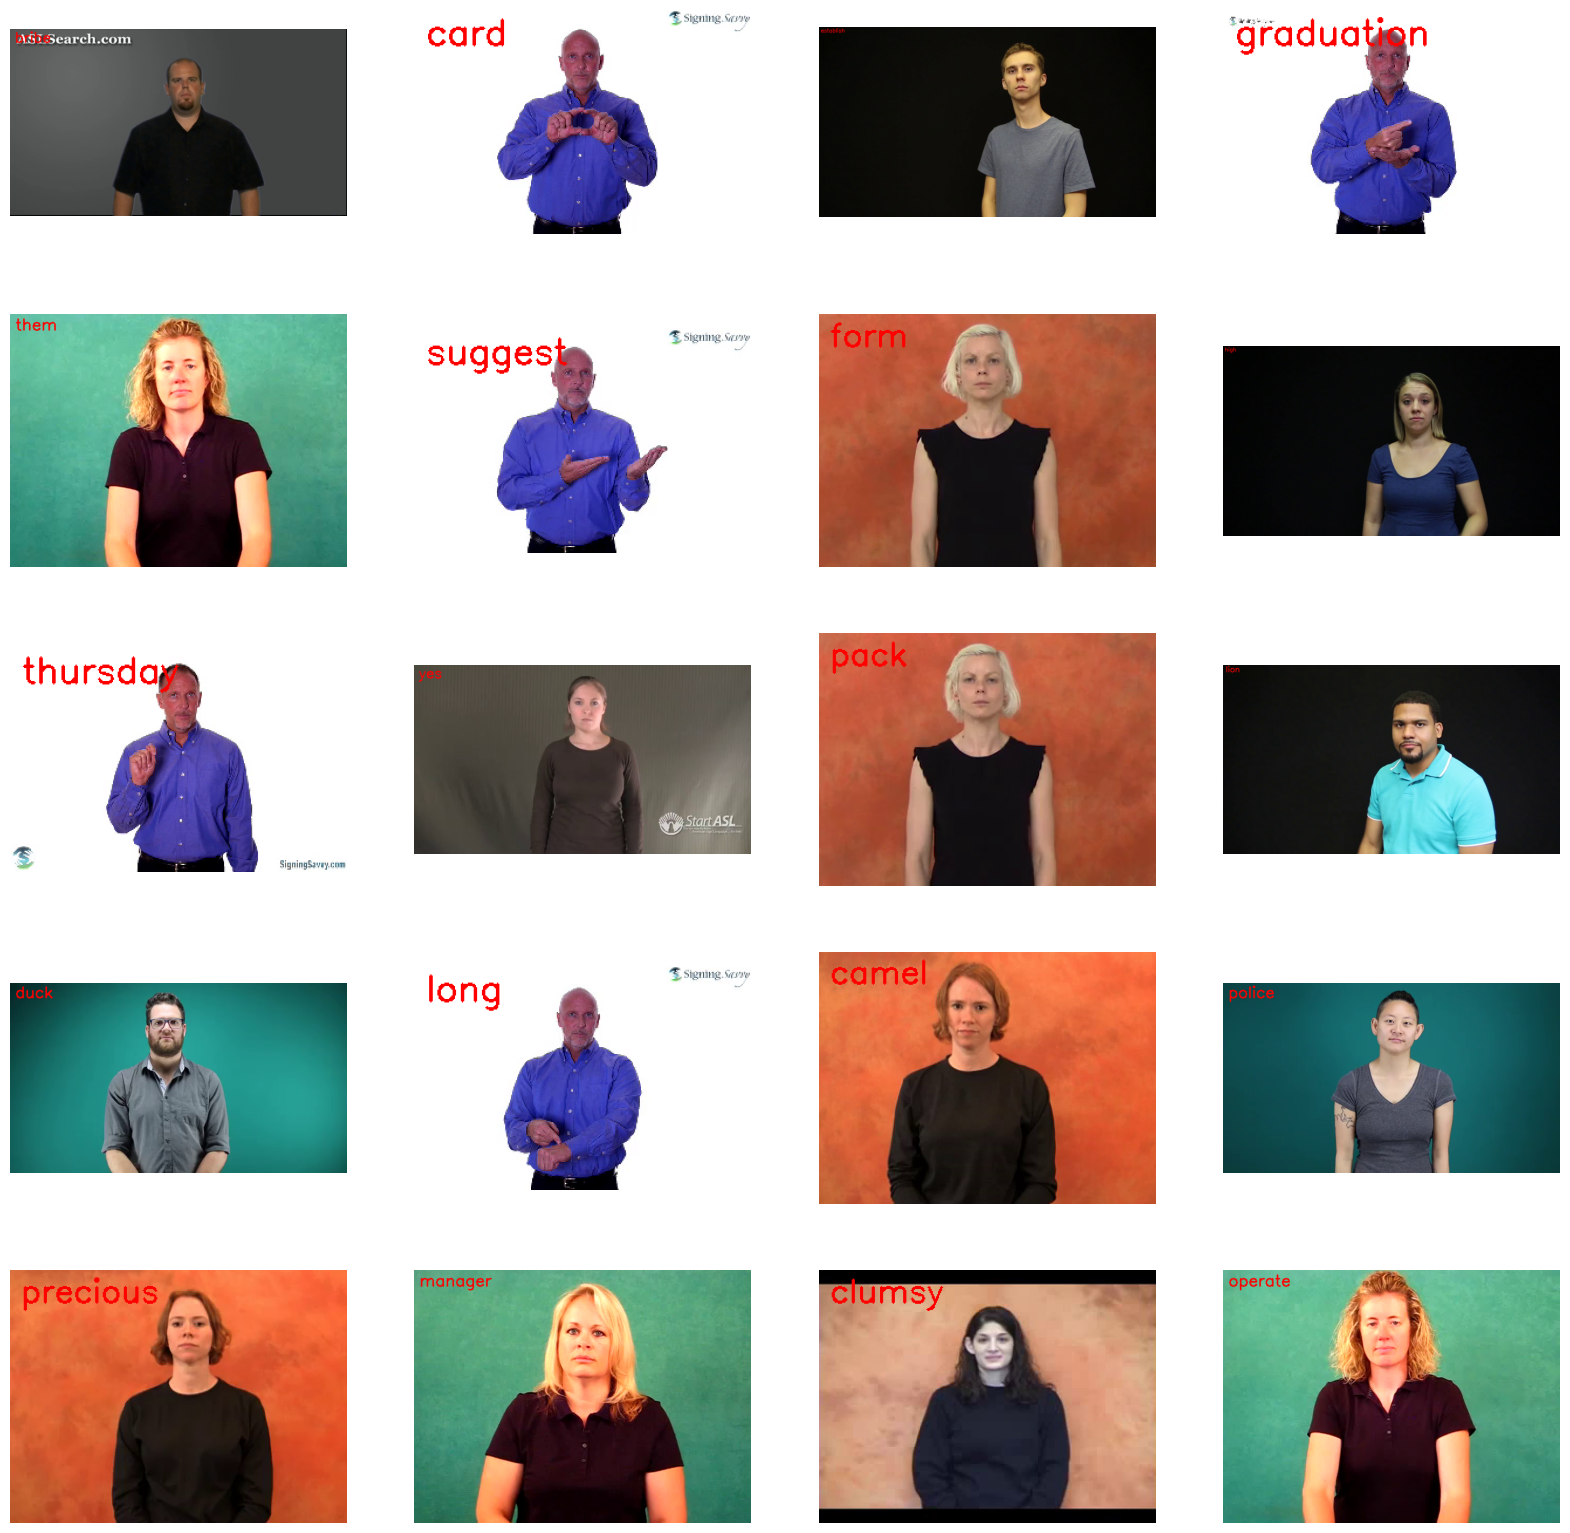

In [20]:
# Create a Matplotlib figure and specify the size of the figure
plt.figure(figsize=(20, 20))

# Get the names of all classes/categories in UCF50
all_classes_names = os.listdir(DATASET_DIR)

# generate a list of 20 random values. The values will be between 0-50 where 50 is the
# total number of classes in the dataset
random_range = random.sample(range(len(all_classes_names)), 20)

# Iterating through all the generated random values.
for counter, random_index in enumerate(random_range, 1):

    # Retrieve the list of all the video files present in the randomly selected Class Directory
    video_files_names_list = os.listdir(DATASET_DIR)

    #Randomly select a video file from the list retrieved from the randomly selected Class Directory.
    selected_video_file_name = random.choice(video_files_names_list)

    # Retrieve a Class Name using the Random Index.
    idx = get_index_of_video(selected_video_file_name.split(".")[0])
    selected_class_Name = features_df.iloc[idx].gloss

    # Initialize a VideoCapture object to read from the video File.
    video_reader = cv2.VideoCapture(f'{DATASET_DIR}{selected_video_file_name}')

    # Read the first frame of the video file
    _, bgr_frame = video_reader.read()

    # release the video object
    video_reader.release()

    #  convert the frame from VGR into RBG format.
    rgb_frame = cv2.cvtColor(bgr_frame, cv2.COLOR_BGR2RGB)

    # Write the class name on the video frame.
    cv2.putText(rgb_frame, selected_class_Name, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 2)

    # Display the frame
    plt.subplot(5, 4, counter); plt.imshow(rgb_frame);plt.axis('off')



In [21]:
def frames_extraction(video_path):
    """
    This function will extract the required frames from a video after resizing and normalizing them.
    Args:
    video_path: The path of the video in the disk, whose frames are to be extracted.

    Returns:
    frames_list: A list containing the resized and normalized frames of the video.
    """

    # Declare a list to store video frames.
    frames_list = []

    # Read the video File using the videoCapture object.
    video_reader = cv2.VideoCapture(video_path)

    # Get the total number of frames in the video.
    video_frames_count = int(video_reader.get(cv2.CAP_PROP_FRAME_COUNT))

    # Calculate the interval after which frames will be added to the list.
    skip_frames_window = max(int(video_frames_count/SEQUENCE_LENGTH), 1)

    # Iterate through the Video frames:
    for frame_counter in range(SEQUENCE_LENGTH):

        # Set the current frame position of the video
        video_reader.set(cv2.CAP_PROP_POS_FRAMES, frame_counter * skip_frames_window)

        # Reading the frame from the video.
        success, frame = video_reader.read()

        # check if the video frame is not successfully read the break the loop
        if not success:
            break

        # Resize the Frame to fixed height and width.
        resized_frame = cv2.resize(frame, (IMAGE_HEIGHT, IMAGE_WIDTH))

        # Normalize the resized frame by dividing it with 255 so that each pixel value then lies wetween 0 and 1
        normalized_frame = resized_frame / 255

        # Append the normalized frame into the frames list
        frames_list.append(normalized_frame)

    # Release the VideoCapture object.
    video_reader.release()

    # return the frames list.
    return frames_list


In [22]:
N, TOP_N_CLASSES = get_N(7)

In [23]:
def create_dataset():
    """
    This function will extract the data of the videos and create the required dataset.
    Retuns:
    features: A list containing the extracted frames of the videos.
    labels :  A list containing the indexes of the classes associated with the video
    video_files_paths :  A list containing the paths of the videos in the disk.
    """

    # Declared Empty Lists to store the features, labels and video file path values.
    features = []
    labels = []
    video_files_paths = []
    split = []


    # Get the list of video files present in the specific class name directory.
    files_list = os.listdir(DATASET_DIR)
    count = 0
    for file_name in files_list:

        # Display the name of the video whose data is being extracted and its number in iterations


        # Get the complete video path.
        video_file_path = os.path.join(DATASET_DIR, file_name)
        idx = get_index_of_video(file_name.split(".")[0])
        selected_class_Name = features_df.iloc[idx].gloss

        if selected_class_Name in TOP_N_CLASSES:
          print(f"Extracting Data of file: {file_name}, number: {count}")

          # Extract the frames of the video file.
          frames = frames_extraction(video_file_path)
          #frames = load_rgb_frames_from_video(DATASET_DIR, file_name, 1, SEQUENCE_LENGTH)

          # check if the extracted frames are equal to the SEQUENCE_LENGTH specified above.
          # So ignore the videos having less than the SEQUENCE_LENGTH.
          if len(frames) == SEQUENCE_LENGTH:

              # get the video's class name
              class_index = features_df.iloc[idx].gloss_indx
              splt = features_df.iloc[idx].split
              # Append the data to their repective list
              features.append(frames)
              labels.append(class_index)
              video_files_paths.append(video_file_path)
              split.append(splt)
              count = count +1


    # Converting the list to numpy arrays
    features = np.asarray(features)
    labels = np.array(labels)
    split = np.asarray(split)

    # Return the frames, class_index and video_file_path
    return features, labels, split

In [24]:
# Creat the dataset
features, labels, split = create_dataset()

Extracting Data of file: 65539.mp4, number: 0
Extracting Data of file: 65540.mp4, number: 1
Extracting Data of file: 65891.mp4, number: 2
Extracting Data of file: 65890.mp4, number: 3
Extracting Data of file: 65889.mp4, number: 4
Extracting Data of file: 65824.mp4, number: 5
Extracting Data of file: 66779.mp4, number: 6
Extracting Data of file: 66607.mp4, number: 7
Extracting Data of file: 66606.mp4, number: 8
Extracting Data of file: 66778.mp4, number: 9
Extracting Data of file: 69281.mp4, number: 10
Extracting Data of file: 69302.mp4, number: 11
Extracting Data of file: 69345.mp4, number: 12
Extracting Data of file: 69364.mp4, number: 13
Extracting Data of file: 69534.mp4, number: 14
Extracting Data of file: 63225.mp4, number: 15
Extracting Data of file: 63226.mp4, number: 16
Extracting Data of file: 63232.mp4, number: 17
Extracting Data of file: 63227.mp4, number: 18
Extracting Data of file: 63229.mp4, number: 19
Extracting Data of file: 63236.mp4, number: 20
Extracting Data of file

In [25]:
train_data = []
train_labels = []
test_data = []
test_labels = []
for i in range(len(split)):
  if split[i]=="train":
    train_data.append(features[i])
    train_labels.append(labels[i])
  else:
    test_data.append(features[i])
    test_labels.append(labels[i])

train_data = np.asarray(train_data)
train_labels = np.array(train_labels)

test_data = np.asarray(test_data)
test_labels = np.array(test_labels)

In [26]:
NB_CLASSES = len(set(train_labels))
NB_CLASSES

7

In [27]:
train_data.shape

(76, 20, 64, 64, 3)

In [ ]:
import tensorflow as tf
ConvLSTM_model_3 = Sequential()
# We will use a Sequential model for model_3 construction.
LRCN_model_3 = Sequential()

# Define the Model Architecture.
########################################################################################################################

LRCN_model_3.add(tf.keras.layers.TimeDistributed(tf.keras.layers.Conv2D(16, (3, 3), padding='same',activation = 'tanh'),
                          input_shape = (SEQUENCE_LENGTH, IMAGE_HEIGHT, IMAGE_WIDTH, 3)))

LRCN_model_3.add(tf.keras.layers.TimeDistributed(tf.keras.layers.MaxPooling2D((4, 4))))
LRCN_model_3.add(tf.keras.layers.TimeDistributed(tf.keras.layers.Dropout(0.25)))

LRCN_model_3.add(tf.keras.layers.TimeDistributed(tf.keras.layers.Conv2D(32, (3, 3), padding='same',activation = 'tanh')))
LRCN_model_3.add(tf.keras.layers.TimeDistributed(tf.keras.layers.MaxPooling2D((4, 4))))
LRCN_model_3.add(tf.keras.layers.TimeDistributed(tf.keras.layers.Dropout(0.25)))

LRCN_model_3.add(tf.keras.layers.TimeDistributed(tf.keras.layers.Conv2D(64, (3, 3), padding='same',activation = 'tanh')))
LRCN_model_3.add(tf.keras.layers.TimeDistributed(tf.keras.layers.MaxPooling2D((2, 2))))
LRCN_model_3.add(tf.keras.layers.TimeDistributed(tf.keras.layers.Dropout(0.25)))

LRCN_model_3.add(tf.keras.layers.TimeDistributed(tf.keras.layers.Conv2D(64, (3, 3), padding='same',activation = 'tanh')))
LRCN_model_3.add(tf.keras.layers.TimeDistributed(tf.keras.layers.MaxPooling2D((2, 2))))
#model.add(TimeDistributed(Dropout(0.25)))

LRCN_model_3.add(tf.keras.layers.TimeDistributed(tf.keras.layers.Flatten()))

LRCN_model_3.add(tf.keras.layers.LSTM(32))

LRCN_model_3.add(tf.keras.layers.Dense(NB_CLASSES, activation = 'softmax'))

########################################################################################################################

# Display the models summary.
LRCN_model_3.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 time_distributed_1 (TimeDi  (None, 20, 64, 64, 16)    448       
 stributed)                                                      
                                                                 
 time_distributed_2 (TimeDi  (None, 20, 16, 16, 16)    0         
 stributed)                                                      
                                                                 
 time_distributed_3 (TimeDi  (None, 20, 16, 16, 16)    0         
 stributed)                                                      
                                                                 
 time_distributed_4 (TimeDi  (None, 20, 16, 16, 32)    4640      
 stributed)                                                      
                                                                 
 time_distributed_5 (TimeDi  (None, 20, 4, 4, 32)     

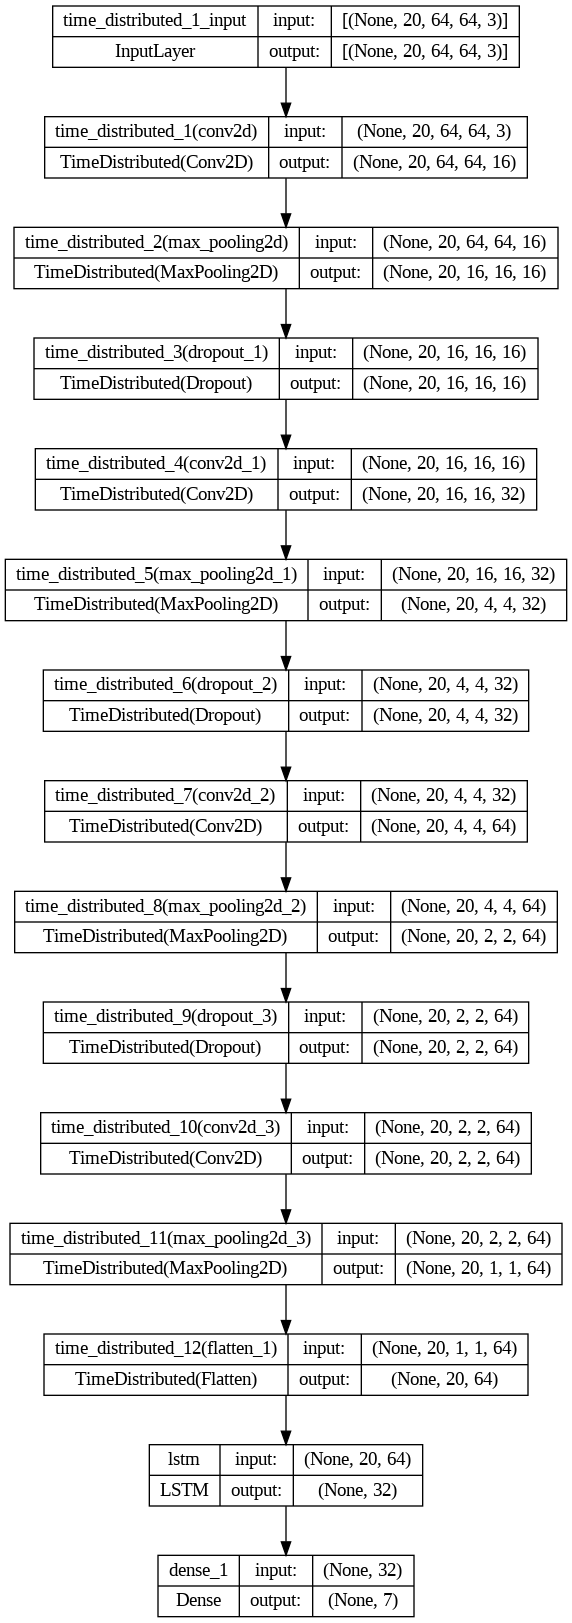

In [ ]:
from tensorflow.keras.utils import plot_model
import matplotlib.pyplot as plt

# Assuming your model is named LRCN_model_3 and has been already defined
plot_model(LRCN_model_3, to_file='LRCN_model_3.png', show_shapes=True, show_layer_names=True)



In [37]:
from keras.callbacks import EarlyStopping, ModelCheckpoint
early_stopping_callback = EarlyStopping(monitor = 'val_loss', patience = 15, mode = 'auto', restore_best_weights = True)

# Compile the model and specify loss function, optimizer and metrics values to the model
LRCN_model_3.compile(loss = 'categorical_crossentropy', optimizer = 'Adam', metrics = ["accuracy"])

# Start training the model.
LRCN_model_3_history = LRCN_model_3.fit(x = train_data, y = tf.one_hot(train_labels, NB_CLASSES), epochs = 30, batch_size = 20,
                                                     validation_data=(train_data, tf.one_hot(train_labels, NB_CLASSES)), callbacks = [early_stopping_callback])

Epoch 1/30
4/4 [==============================] - 34s 8s/step - loss: 0.4104 - accuracy: 0.8816 - val_loss: 0.1084 - val_accuracy: 0.9737
Epoch 2/30
4/4 [==============================] - 22s 6s/step - loss: 0.3312 - accuracy: 0.8816 - val_loss: 0.3776 - val_accuracy: 0.8289
Epoch 3/30
4/4 [==============================] - 28s 7s/step - loss: 0.1653 - accuracy: 0.9474 - val_loss: 0.1479 - val_accuracy: 0.9737
Epoch 4/30
4/4 [==============================] - 27s 7s/step - loss: 0.2152 - accuracy: 0.9605 - val_loss: 0.0972 - val_accuracy: 0.9737
Epoch 5/30
4/4 [==============================] - 27s 8s/step - loss: 0.0633 - accuracy: 0.9868 - val_loss: 0.0976 - val_accuracy: 0.9737
Epoch 6/30
4/4 [==============================] - 22s 6s/step - loss: 0.0631 - accuracy: 0.9868 - val_loss: 0.0757 - val_accuracy: 0.9868
Epoch 7/30
4/4 [==============================] - 24s 6s/step - loss: 0.0407 - accuracy: 1.0000 - val_loss: 0.0448 - val_accuracy: 1.0000
Epoch 8/30
4/4 [==================

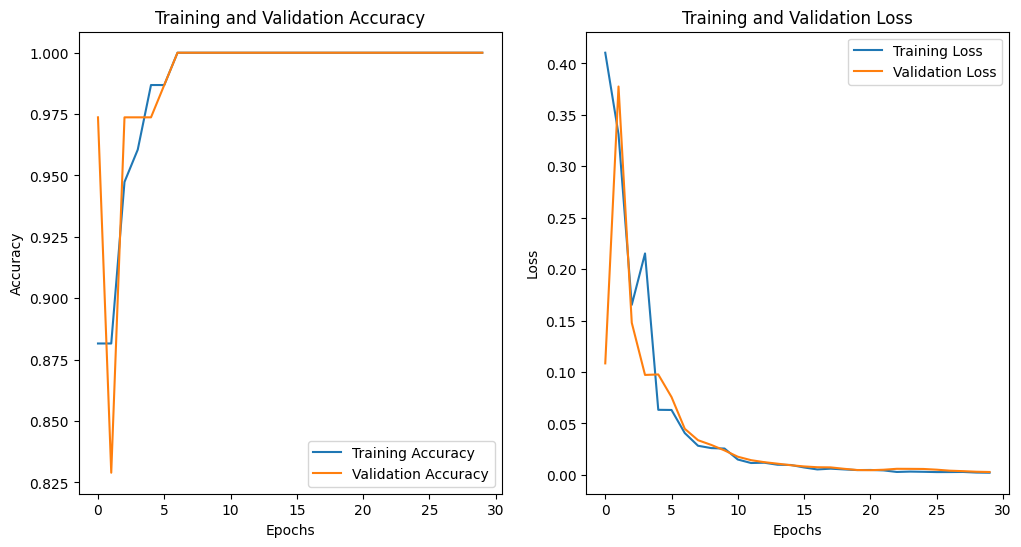

In [38]:
import matplotlib.pyplot as plt


# Plot the training and validation accuracy
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.plot(LRCN_model_3_history.history['accuracy'], label='Training Accuracy')
plt.plot(LRCN_model_3_history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Plot the training and validation loss
plt.subplot(1, 2, 2)
plt.plot(LRCN_model_3_history.history['loss'], label='Training Loss')
plt.plot(LRCN_model_3_history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()


In [ ]:
from tensorflow.keras.utils import to_categorical

# Assuming labels are not one-hot encoded
train_labels = to_categorical(train_labels, num_classes=NB_CLASSES)
test_labels = to_categorical(test_labels, num_classes=NB_CLASSES)


3/3 [==============================] - 9s 2s/step
Classification Report:
               precision    recall  f1-score   support

        cool       1.00      1.00      1.00        11
      before       1.00      1.00      1.00        12
        thin       1.00      1.00      1.00        11
          go       1.00      1.00      1.00        11
       drink       1.00      1.00      1.00        11
        help       1.00      1.00      1.00        10
         who       1.00      1.00      1.00        10

    accuracy                           1.00        76
   macro avg       1.00      1.00      1.00        76
weighted avg       1.00      1.00      1.00        76



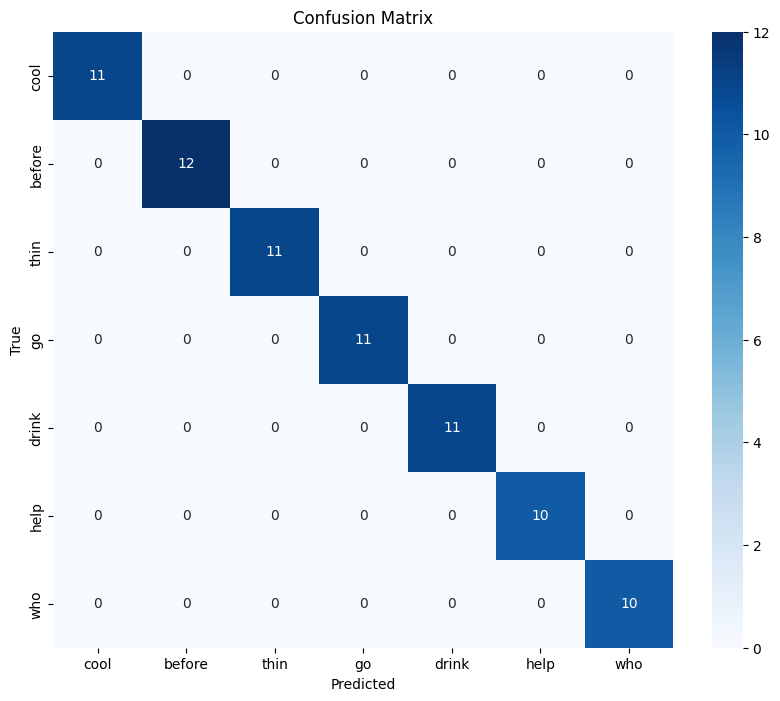

In [45]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import numpy as np

# Predict the labels for the test data
test_predictions = LRCN_model_3.predict(test_data)
test_predictions_classes = np.argmax(test_predictions, axis=1)


# Generate the classification report
class_names = ['cool', 'before', 'thin', 'go', 'drink', 'help', 'who']   # Replace with your actual class names
report = classification_report(test_predictions_classes, test_labels, target_names=class_names)
print("Classification Report:\n", report)

# Generate the confusion matrix
conf_matrix = confusion_matrix(test_labels, test_predictions_classes)

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()


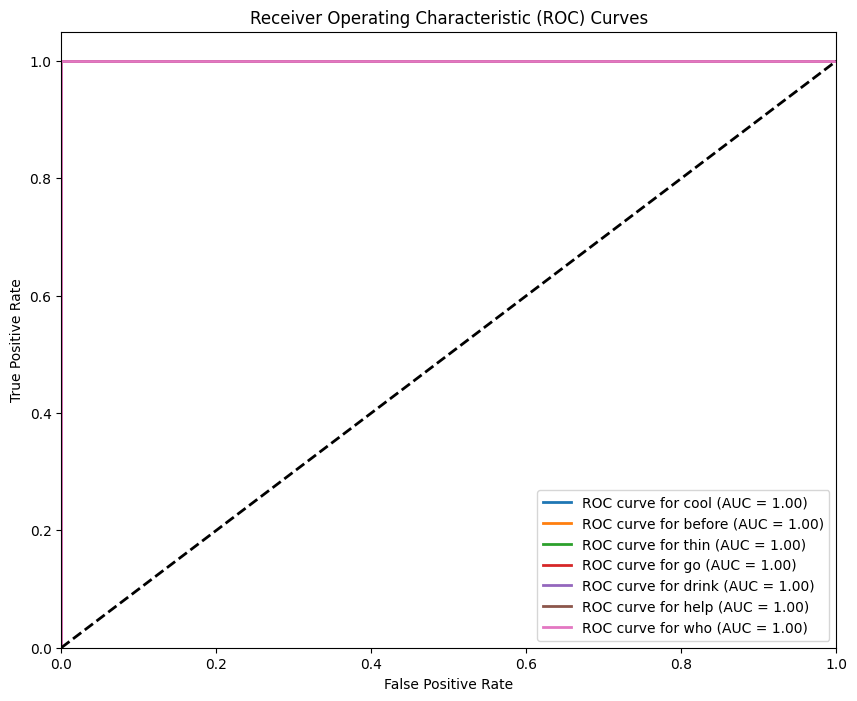

In [46]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

# Convert true labels to one-hot encoded vectors
true_labels_binarized = label_binarize(test_labels, classes=np.arange(len(class_names)))

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(len(class_names)):
    fpr[i], tpr[i], _ = roc_curve(true_labels_binarized[:, i], test_predictions[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot ROC curves for each class
plt.figure(figsize=(10, 8))
for i in range(len(class_names)):
    plt.plot(fpr[i], tpr[i], lw=2, label='ROC curve for {} (AUC = {:.2f})'.format(class_names[i], roc_auc[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curves')
plt.legend(loc='lower right')
plt.show()


**Hagri Dataset**

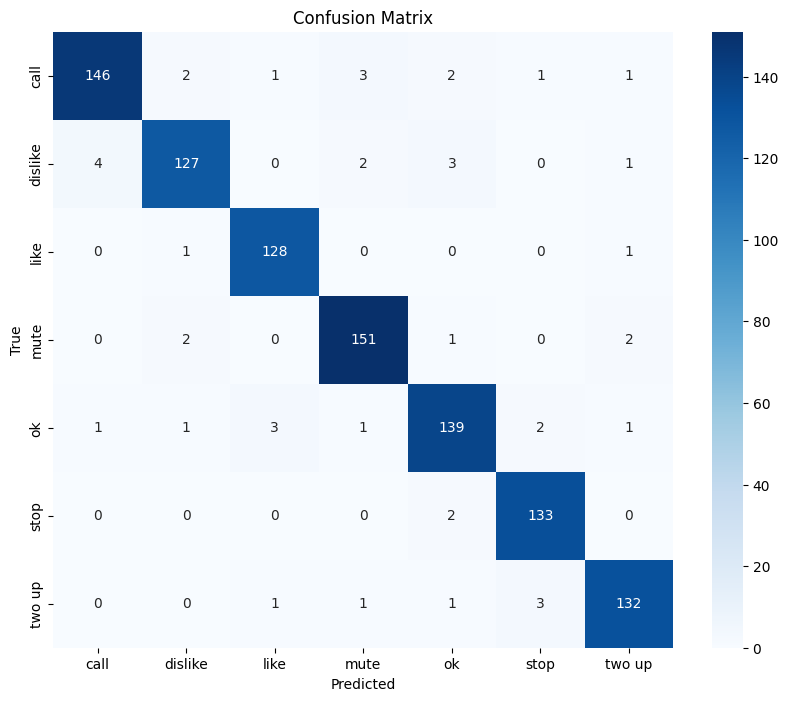

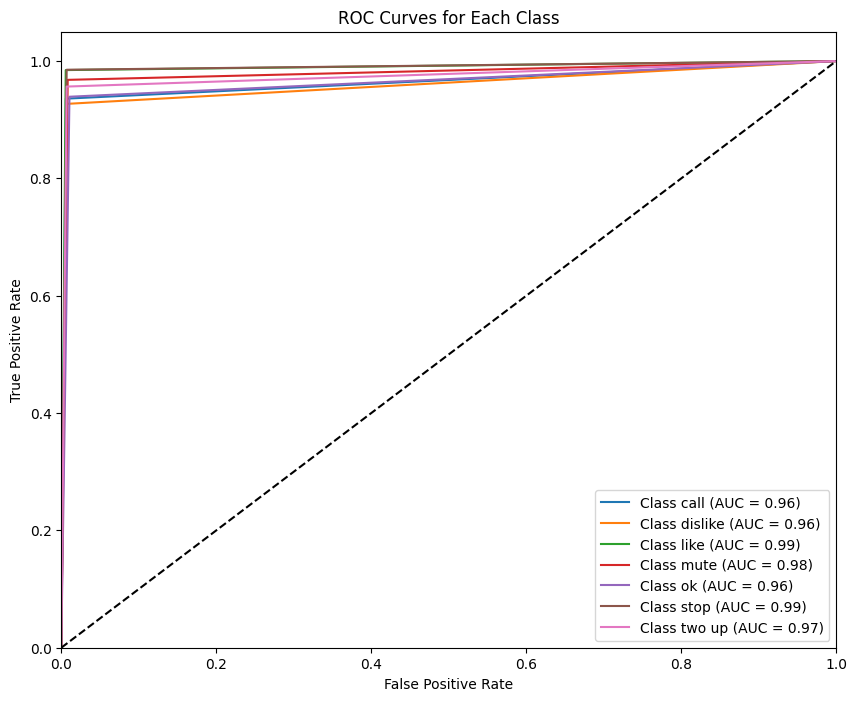

Classification Report:
               precision    recall  f1-score   support

        call       0.97      0.94      0.95       156
     dislike       0.95      0.93      0.94       137
        like       0.96      0.98      0.97       130
        mute       0.96      0.97      0.96       156
          ok       0.94      0.94      0.94       148
        stop       0.96      0.99      0.97       135
      two up       0.96      0.96      0.96       138

    accuracy                           0.96      1000
   macro avg       0.96      0.96      0.96      1000
weighted avg       0.96      0.96      0.96      1000



In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.preprocessing import label_binarize
import seaborn as sns

# Define the class names
class_names = ['call', 'dislike', 'like', 'mute', 'ok', 'stop', 'two up']


num_classes = len(class_names)


#

test_predictions = np.array(test_predictions)

# Compute the confusion matrix
conf_matrix = confusion_matrix(test_labels, test_predictions)

# Plot the confusion matrix heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Binarize the labels for ROC curve computation
test_labels_binarized = label_binarize(test_labels, classes=range(num_classes))
predictions_binarized = label_binarize(test_predictions, classes=range(num_classes))

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(test_labels_binarized[:, i], predictions_binarized[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot ROC curves for each class
plt.figure(figsize=(10, 8))
for i in range(num_classes):
    plt.plot(fpr[i], tpr[i], label=f'Class {class_names[i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--')  # Diagonal line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for Each Class')
plt.legend(loc='lower right')
plt.show()

# Print classification report
report = classification_report(test_labels, test_predictions, target_names=class_names)
print("Classification Report:\n", report)


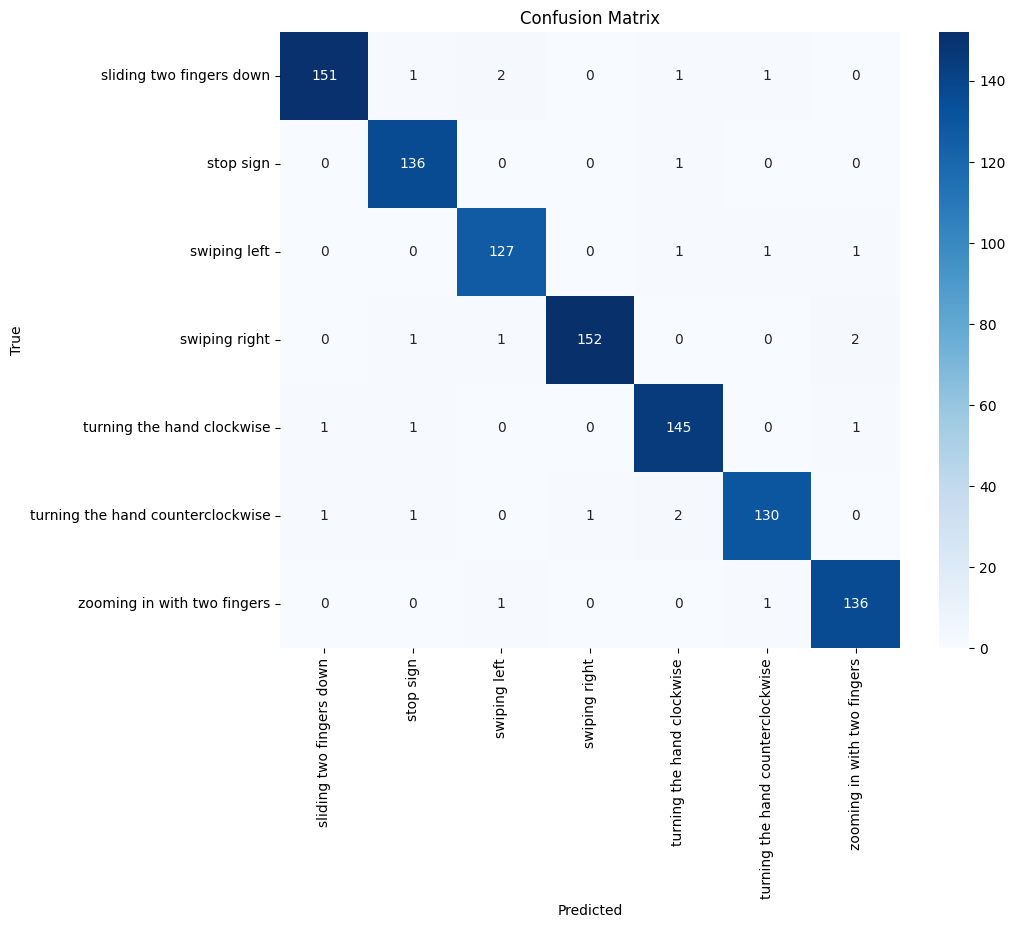

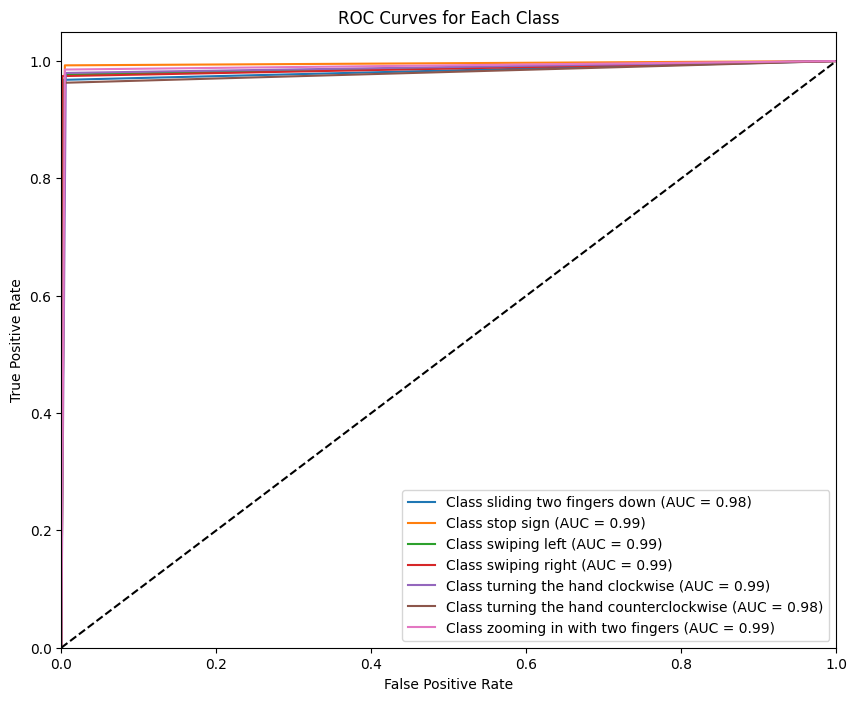

Classification Report:
                                    precision    recall  f1-score   support

         sliding two fingers down       0.99      0.97      0.98       156
                        stop sign       0.97      0.99      0.98       137
                     swiping left       0.97      0.98      0.97       130
                    swiping right       0.99      0.97      0.98       156
       turning the hand clockwise       0.97      0.98      0.97       148
turning the hand counterclockwise       0.98      0.96      0.97       135
      zooming in with two fingers       0.97      0.99      0.98       138

                         accuracy                           0.98      1000
                        macro avg       0.98      0.98      0.98      1000
                     weighted avg       0.98      0.98      0.98      1000



In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.preprocessing import label_binarize
import seaborn as sns

# Define the class names
class_names = ['sliding two fingers down', 'stop sign', 'swiping left', 'swiping right',
               'turning the hand clockwise', 'turning the hand counterclockwise', 'zooming in with two fingers']


num_classes = len(class_names)





test_predictions = np.array(test_predictions)

# Compute the confusion matrix
conf_matrix = confusion_matrix(test_labels, test_predictions)

# Plot the confusion matrix heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Binarize the labels for ROC curve computation
true_labels_binarized = label_binarize(test_labels, classes=range(num_classes))
predictions_binarized = label_binarize(test_predictions, classes=range(num_classes))

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(true_labels_binarized[:, i], predictions_binarized[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot ROC curves for each class
plt.figure(figsize=(10, 8))
for i in range(num_classes):
    plt.plot(fpr[i], tpr[i], label=f'Class {class_names[i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--')  # Diagonal line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for Each Class')
plt.legend(loc='lower right')
plt.show()

# Print classification report
report = classification_report(test_labels, test_predictions, target_names=class_names)
print("Classification Report:\n", report)
